# 02 — Preparação, modelagem e escolha do classificador

**Projeto Integrador:** Predição de Churn em Clientes de Telecomunicações utilizando Machine Learning

Este caderno cobre as **Etapas 4 a 21** do enunciado:

- separar a variável-alvo e as preditoras;
- criar conjuntos de treino e teste com estratificação;
- montar um *pipeline* único de preparação (`ColumnTransformer` + `OneHotEncoder` + imputação/escalonamento);
- treinar e comparar **três** modelos (Regressão Logística, Árvore de Decisão e *Random Forest*);
- escolher o modelo com base principalmente no *recall* da classe *Churn* e no F1-score;
- salvar o **pipeline completo** (preparação + classificador) em `models/churn_model.joblib`.

A aplicação Streamlit deverá reutilizar exatamente este objeto salvo, para que o tratamento dos dados no uso seja o mesmo do treinamento.

## Bibliotecas e reprodução da limpeza

In [1]:
%matplotlib inline
from pathlib import Path
import os

# Garante execução a partir da raiz do projeto, tanto no Jupyter
# (quando o caderno é aberto em notebooks/) quanto via nbconvert.
raiz = Path.cwd()
if not (raiz / "data" / "WA_Fn-UseC_-Telco-Customer-Churn.csv").exists():
    candidata = raiz / ".." if raiz.name == "notebooks" else raiz.parent
    candidata = candidata.resolve()
    if (candidata / "data" / "WA_Fn-UseC_-Telco-Customer-Churn.csv").exists():
        os.chdir(candidata)

print("Diretório de trabalho:", Path.cwd())

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import joblib

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report,
    ConfusionMatrixDisplay,
    RocCurveDisplay,
)

pd.set_option("display.max_columns", None)
plt.rcParams.update({
    "figure.figsize": (6, 4.5),
    "axes.titlesize": 12,
    "axes.spines.top": False,
    "axes.spines.right": False,
})

RANDOM_STATE = 42
CAMINHO_MODELO = "models/churn_model.joblib"


Diretório de trabalho: /workspace/telco-churn


In [2]:
df = pd.read_csv("data/WA_Fn-UseC_-Telco-Customer-Churn.csv")

# Mesmo tratamento justificado no caderno 01:
# TotalCharges em branco (11 linhas, tenure = 0) recebe 0.
df["TotalCharges"] = pd.to_numeric(df["TotalCharges"], errors="coerce")
n_ausentes = int(df["TotalCharges"].isna().sum())
df["TotalCharges"] = df["TotalCharges"].fillna(0)

print(f"Registros: {len(df)}")
print(f"TotalCharges convertida; valores imputados com zero: {n_ausentes}")
print("Ausentes restantes:", int(df.isnull().sum().sum()))


Registros: 7043
TotalCharges convertida; valores imputados com zero: 11
Ausentes restantes: 0


## Etapa 4 — Separar variável-alvo e preditoras

A variável `Churn` é convertida para forma binária (`No = 0`, `Yes = 1`). O `customerID` identifica o cliente e **não** entra como preditora — seria um código sem significado generalizável e poderia até vazar identidade, mas não padrão de negócio.

In [3]:
X = df.drop(columns=["Churn", "customerID"])
y = df["Churn"].map({"No": 0, "Yes": 1})

print("Dimensão de X:", X.shape)
print("Distribuição de y:")
print(y.value_counts().rename({0: "No (0)", 1: "Yes (1)"}))
print("\nProporção:")
print(y.value_counts(normalize=True).rename({0: "No (0)", 1: "Yes (1)"}).round(4))
print("\nColunas preditoras:")
print(list(X.columns))


Dimensão de X: (7043, 19)
Distribuição de y:
Churn
No (0)     5174
Yes (1)    1869
Name: count, dtype: int64

Proporção:
Churn
No (0)     0.7346
Yes (1)    0.2654
Name: proportion, dtype: float64

Colunas preditoras:
['gender', 'SeniorCitizen', 'Partner', 'Dependents', 'tenure', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod', 'MonthlyCharges', 'TotalCharges']


## Etapa 5 — Separar treino e teste

Usamos 80% dos dados para treino e 20% para teste, com `random_state=42` (reprodutibilidade) e `stratify=y`. A estratificação preserva, aproximadamente, a mesma proporção de *churn* nos dois conjuntos. Sem ela, o conjunto de teste poderia ficar artificialmente mais fácil ou mais difícil só por acaso da divisão.

In [4]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=RANDOM_STATE,
    stratify=y,
)

print("X_train:", X_train.shape, "| X_test:", X_test.shape)
print("\nProporção de churn no treino:", f"{y_train.mean():.4f}")
print("Proporção de churn no teste: ", f"{y_test.mean():.4f}")
print("\nContagem no teste (0 = permaneceu, 1 = saiu):")
print(y_test.value_counts())


X_train: (5634, 19) | X_test: (1409, 19)

Proporção de churn no treino: 0.2654
Proporção de churn no teste:  0.2654

Contagem no teste (0 = permaneceu, 1 = saiu):
Churn
0    1035
1     374
Name: count, dtype: int64


## Etapa 6 — Preparação automática dos dados (*pipeline*)

Não transformamos as colunas “na mão” de forma isolada. Um único `ColumnTransformer` cuida de:

- **numéricas** (`tenure`, `MonthlyCharges`, `TotalCharges`): imputação (rede de segurança) e `StandardScaler`, importante sobretudo para a regressão logística, que é sensível à escala;
- **categóricas** (demais preditoras, inclusive `SeniorCitizen`, que é um indicador 0/1): imputação pela moda e `OneHotEncoder` com `handle_unknown="ignore"`, para a aplicação não quebrar caso receba uma categoria inesperada.

Esse bloco de preparação será encaixado no mesmo `Pipeline` do classificador. Assim, o objeto gravado em disco já sabe transformar um cliente novo exatamente como os dados de treino foram transformados.

In [5]:
variaveis_numericas = ["tenure", "MonthlyCharges", "TotalCharges"]
variaveis_categoricas = [coluna for coluna in X.columns if coluna not in variaveis_numericas]

print("Numéricas:", variaveis_numericas)
print("Categóricas:", variaveis_categoricas)

transformador_numerico = Pipeline(
    steps=[
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
    ]
)

transformador_categorico = Pipeline(
    steps=[
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("onehot", OneHotEncoder(handle_unknown="ignore")),
    ]
)

preprocessador = ColumnTransformer(
    transformers=[
        ("num", transformador_numerico, variaveis_numericas),
        ("cat", transformador_categorico, variaveis_categoricas),
    ]
)

preprocessador


Numéricas: ['tenure', 'MonthlyCharges', 'TotalCharges']
Categóricas: ['gender', 'SeniorCitizen', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod']


,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different transformers contains sparse matrices,these will be stacked as a sparse matrix if the overall density islower than this value. Use ``sparse_threshold=0`` to always returndense. When the transformed output consists of all dense data, thestacked result will be dense, and this keyword will be ignored.",0.3
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details.",None
,"transformer_weights transformer_weights: dict, default=NoneMultiplicative weights for features per transformer. The output of thetransformer is multiplied by these weights. Keys are transformer names,values the weights.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each transformer will beprinted as it is completed.",False
,"verbose_feature_names_out verbose_feature_names_out: bool, str or Callable[[str, str], str], default=True- If True, :meth:`ColumnTransformer.get_feature_names_out` will prefix all feature names with the name of the transformer that generated that feature. It is equivalent to setting `verbose_feature_names_out=""{transformer_name}__{feature_name}""`.- If False, :meth:`ColumnTransformer.get_feature_names_out` will not prefix any feature names and will error if feature names are not unique.- If ``Callable[[str, str], str]``, :meth:`ColumnTransformer.get_feature_names_out` will rename all the features using the name of the transformer. The first argument of the callable is the transformer name and the second argument is the feature name. The returned string will be the new feature name.- If ``str``, it must be a string ready for formatting. The given string will be formatted using two field names: ``transformer_name`` and ``feature_name``

## Modelos comparados

Comparamos apenas os três algoritmos pedidos no enunciado:

1. **Regressão Logística** — *baseline* interpretável;
2. **Árvore de Decisão** — regras hierárquicas, fáceis de explicar, porém propensas a sobreajuste se não limitadas;
3. **Random Forest** — conjunto de árvores, em geral mais estável do que uma árvore isolada.

### Uso de `class_weight="balanced"`

A classe *Churn* representa cerca de **26,5%** dos casos. Sem ajuste, os algoritmos tendem a privilegiar a classe majoritária e a deixar de identificar quem cancela — exatamente o erro mais grave neste problema.

A opção `class_weight="balanced"` ajusta o peso das classes de forma inversamente proporcional à frequência. Isso costuma **aumentar o recall** da classe positiva, em troca de alguma queda de precisão e, às vezes, de acurácia. Como o critério principal do projeto é o *recall* da classe *Churn* e o F1-score, adotamos `class_weight="balanced"` nos três modelos e justificamos a escolha com as métricas abaixo.

Hiperparâmetros adicionais foram mantidos só o necessário para um treino estável e reproduzível (`random_state=42`, `max_iter=1000` na regressão e `n_estimators=200` na floresta). Não foi feita uma “copa do mundo” de algoritmos nem uma busca exaustiva de hiperparâmetros.

In [6]:
modelos = {
    "Regressão Logística": LogisticRegression(
        max_iter=1000,
        class_weight="balanced",
        random_state=RANDOM_STATE,
    ),
    "Árvore de Decisão": DecisionTreeClassifier(
        class_weight="balanced",
        random_state=RANDOM_STATE,
    ),
    "Random Forest": RandomForestClassifier(
        n_estimators=200,
        class_weight="balanced",
        random_state=RANDOM_STATE,
    ),
}


def treinar_e_avaliar(nome, classificador, preprocessador, X_train, y_train, X_test, y_test):
    pipeline = Pipeline(
        steps=[
            ("preprocessador", preprocessador),
            ("classificador", classificador),
        ]
    )
    pipeline.fit(X_train, y_train)

    y_pred = pipeline.predict(X_test)
    y_proba = pipeline.predict_proba(X_test)[:, 1]

    metricas = {
        "Modelo": nome,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred, pos_label=1),
        "Recall": recall_score(y_test, y_pred, pos_label=1),
        "F1": f1_score(y_test, y_pred, pos_label=1),
        "ROC-AUC": roc_auc_score(y_test, y_proba),
    }
    return pipeline, y_pred, y_proba, metricas


resultados = []
artefatos = {}

for nome, classificador in modelos.items():
    pipeline, y_pred, y_proba, metricas = treinar_e_avaliar(
        nome, classificador, preprocessador, X_train, y_train, X_test, y_test
    )
    artefatos[nome] = {"pipeline": pipeline, "y_pred": y_pred, "y_proba": y_proba}
    resultados.append(metricas)
    print(f"\n===== {nome} =====")
    print(classification_report(y_test, y_pred, target_names=["Não churn (0)", "Churn (1)"], digits=4))
    print("Matriz de confusão (linhas = real, colunas = previsto):")
    print(confusion_matrix(y_test, y_pred))
    print("ROC-AUC:", f"{metricas['ROC-AUC']:.4f}")



===== Regressão Logística =====
               precision    recall  f1-score   support

Não churn (0)     0.9022    0.7217    0.8019      1035
    Churn (1)     0.5043    0.7834    0.6136       374

     accuracy                         0.7381      1409
    macro avg     0.7032    0.7526    0.7078      1409
 weighted avg     0.7966    0.7381    0.7519      1409

Matriz de confusão (linhas = real, colunas = previsto):
[[747 288]
 [ 81 293]]
ROC-AUC: 0.8415



===== Árvore de Decisão =====
               precision    recall  f1-score   support

Não churn (0)     0.8151    0.8135    0.8143      1035
    Churn (1)     0.4867    0.4893    0.4880       374

     accuracy                         0.7275      1409
    macro avg     0.6509    0.6514    0.6512      1409
 weighted avg     0.7279    0.7275    0.7277      1409

Matriz de confusão (linhas = real, colunas = previsto):
[[842 193]
 [191 183]]
ROC-AUC: 0.6517



===== Random Forest =====
               precision    recall  f1-score   support

Não churn (0)     0.8567    0.8145    0.8351      1035
    Churn (1)     0.5482    0.6230    0.5832       374

     accuracy                         0.7637      1409
    macro avg     0.7025    0.7187    0.7091      1409
 weighted avg     0.7748    0.7637    0.7682      1409

Matriz de confusão (linhas = real, colunas = previsto):
[[843 192]
 [141 233]]
ROC-AUC: 0.8242


### Matrizes de confusão

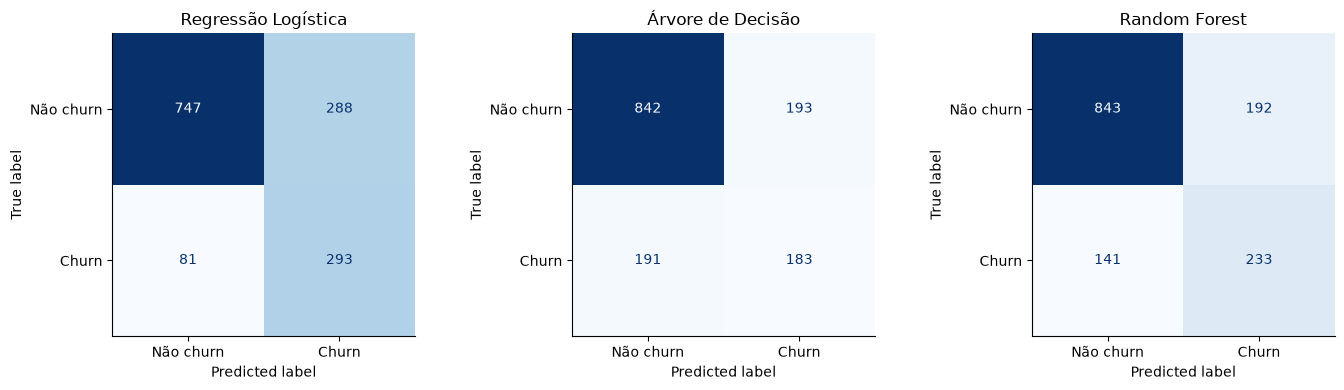

In [7]:
fig, eixos = plt.subplots(1, 3, figsize=(14, 4))
for ax, nome in zip(eixos, modelos.keys()):
    ConfusionMatrixDisplay(
        confusion_matrix=confusion_matrix(y_test, artefatos[nome]["y_pred"]),
        display_labels=["Não churn", "Churn"],
    ).plot(ax=ax, cmap="Blues", colorbar=False)
    ax.set_title(nome)
plt.tight_layout()
plt.show()


### Curvas ROC

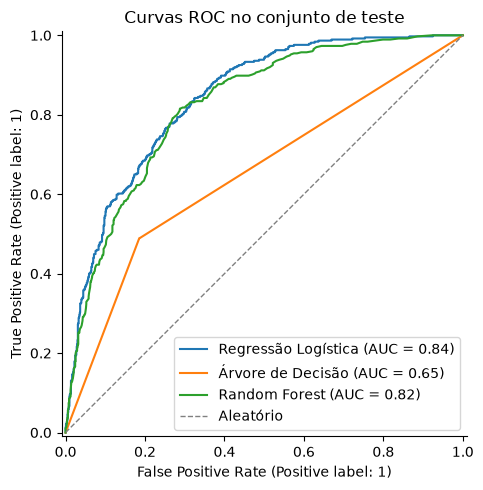

In [8]:
fig, ax = plt.subplots(figsize=(7, 5))
for nome in modelos.keys():
    RocCurveDisplay.from_predictions(
        y_test,
        artefatos[nome]["y_proba"],
        name=nome,
        ax=ax,
    )
ax.plot([0, 1], [0, 1], linestyle="--", color="gray", linewidth=1, label="Aleatório")
ax.set_title("Curvas ROC no conjunto de teste")
ax.legend(loc="lower right")
plt.tight_layout()
plt.show()


## Comparação das métricas e escolha do modelo

In [9]:
tabela = pd.DataFrame(resultados).set_index("Modelo")
tabela_formatada = tabela.map(lambda v: f"{v:.4f}")
tabela_formatada


,Accuracy,Precision,Recall,F1,ROC-AUC
Modelo,,,,,
Regressão Logística,0.7381,0.5043,0.7834,0.6136,0.8415
Árvore de Decisão,0.7275,0.4867,0.4893,0.4880,0.6517
Random Forest,0.7637,0.5482,0.6230,0.5832,0.8242


### Tabela-resumo (conjunto de teste, 1.409 clientes, 374 com *churn*)

| Modelo              | Accuracy | Precision | Recall | F1     | ROC-AUC |
| ------------------- | -------: | --------: | -----: | -----: | ------: |
| Regressão Logística |   0,7381 |    0,5043 | 0,7834 | 0,6136 |  0,8415 |
| Árvore de Decisão   |   0,7275 |    0,4867 | 0,4893 | 0,4880 |  0,6517 |
| Random Forest       |   0,7637 |    0,5482 | 0,6230 | 0,5832 |  0,8242 |

*Valores arredondados em quatro casas; a tabela gerada na célula anterior é a fonte exata.*

### Modelo escolhido: **Regressão Logística** (`class_weight="balanced"`)

**Justificativa:**

O enunciado pede que a escolha se apoie principalmente no **recall da classe *Churn*** e no **F1-score**, sem abandonar ROC-AUC e a matriz de confusão.

- A **Regressão Logística** obteve o melhor *recall* (**0,7834**): de 374 clientes que de fato cancelaram no teste, **293** foram identificados (81 falsos negativos). A Árvore identificou apenas 183 e a *Random Forest*, 233.
- Também teve o melhor **F1** (**0,6136**), o que indica o melhor equilíbrio entre precisão e *recall* entre os três.
- O **ROC-AUC (0,8415)** foi o mais alto, praticamente empatado com a floresta (0,8242) e bem acima da árvore (0,6517). A árvore, sem limite de profundidade, mostra sinal claro de sobreajuste: acerta menos a ordenação de risco.
- A *Random Forest* teve a **melhor acurácia (0,7637)** e a melhor precisão (0,5482). Mesmo assim, deixou de capturar mais clientes que cancelam. Neste problema, um falso negativo (deixar de olhar para quem vai sair) é, em geral, mais custoso do que um falso positivo (acionar um cliente que permaneceria).
- A precisão da regressão (**0,5043**) mostra o custo do *recall* alto: há 288 falsos positivos. Isso deve ser dito com clareza. A aplicação não deve disparar descontos automaticamente; ela apenas apoia a análise humana.

Por essas razões, o *pipeline* da **Regressão Logística** é o modelo final serializado para a aplicação.

## Salvar o *pipeline* completo

Gravamos o objeto inteiro (`preprocessador` + classificador), e não apenas o algoritmo. A aplicação carrega esse arquivo e aplica as mesmas transformações vistas no treino.

In [10]:
modelo_final = artefatos["Regressão Logística"]["pipeline"]

joblib.dump(modelo_final, CAMINHO_MODELO)
print(f"Pipeline salvo em: {CAMINHO_MODELO}")

# Verificação imediata: recarregar e prever o mesmo conjunto de teste
modelo_recarregado = joblib.load(CAMINHO_MODELO)
pred_original = modelo_final.predict_proba(X_test)[:, 1]
pred_recarregado = modelo_recarregado.predict_proba(X_test)[:, 1]
print("Recarga consistente:", np.allclose(pred_original, pred_recarregado))
print("Tipo do objeto salvo:", type(modelo_final))
print("Etapas do pipeline:", list(modelo_final.named_steps.keys()))


Pipeline salvo em: models/churn_model.joblib
Recarga consistente: True
Tipo do objeto salvo: <class 'sklearn.pipeline.Pipeline'>
Etapas do pipeline: ['preprocessador', 'classificador']


## Encerramento da modelagem

- Treino e teste foram separados com `test_size=0,20`, `random_state=42` e `stratify=y`.
- A preparação ficou encapsulada em um `Pipeline` reutilizável.
- Três modelos foram comparados com *accuracy*, *precision*, *recall*, F1, ROC-AUC e matriz de confusão.
- A **Regressão Logística** com `class_weight="balanced"` foi escolhida por apresentar o melhor *recall* da classe *Churn* (0,7834) e o melhor F1 (0,6136), além do maior ROC-AUC (0,8415).
- O *pipeline* completo está em `models/churn_model.joblib`, pronto para a aplicação Streamlit (`app.py`).